# 05b · Transfer learning on the STYLES: a pretrained ResNet18 (deliverable 3)

A dense network flattens the painting and loses its 2-D structure (S05, S07). A **convolutional** network looks at small neighbourhoods with the same filters everywhere, and builds edges → textures → object parts → objects, layer after layer (S07).
With only ~5 200 training images we do not train a CNN from scratch: we start from a **ResNet18 pretrained on ImageNet** (1.2 million photos) and adapt it to our genres, as in TP07 Part D:

1. replace its last layer by a new one for our classes, **freeze** the rest and train the **head** only;
2. paintings are very different from ImageNet photos (S07, transfer-learning table): **unfreeze the last block** (`layer4`) and **fine-tune** it with a smaller learning rate;
3. compare both on validation, measure the chosen one **once** on the test set, with its CPU cost for the kiosk.

## 0. Setup

In [1]:
import copy, json, math, sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, "../src")                 # the team's shared code
from museum_guide.data import prepare_subset

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

ROOT = Path("..")
LABEL = "style"           # this notebook: the 27 styles (05_resnet = genres)
IMG_SIZE = 128            # our images are 128x128 (TP07 uses 64 on a CPU; 224 = ImageNet, more accurate but slower)
FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "data" / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)    # weights stay out of Git
print("device:", device)

device: mps


## 1. Prepare the images like the pre-training
*"A pretrained model must always receive inputs prepared like during its pre-training"* (TP07): resize, then normalise each channel with the **ImageNet** mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225) (S07).
`prepare_subset` gives the team's split (same images as every other model) but standardised with *our* statistics: we undo that first, back to pixels in [0, 1].

In [2]:
data = prepare_subset(LABEL, seed=SEED)
BASE = json.loads((RES_DIR / "baseline_logreg_style.json").read_text())   # baseline on the same task
class_names = data["classes"]
C = len(class_names)
idx = {"train": data["train_idx"], "val": data["val_idx"], "test": data["test_idx"]}

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prepare(X):
    X = X * data["std"] + data["mean"]                                           # undo the team standardisation: [0, 1]
    X = F.interpolate(X, size=IMG_SIZE, mode="bilinear", align_corners=False)    # resize
    return (X - IMAGENET_MEAN) / IMAGENET_STD                                    # ImageNet normalisation


X_img = prepare(data["X"])
y_all = data["y"]
data["X"] = None                                                                 # free the memory

full_set = TensorDataset(X_img, y_all)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(Subset(full_set, idx["train"]), batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(Subset(full_set, idx["val"]), batch_size=128)
test_loader = DataLoader(Subset(full_set, idx["test"]), batch_size=128)

print(C, "classes:", class_names)
print("images:", tuple(X_img.shape), "|", {s: len(i) for s, i in idx.items()})
print("train mean per channel:", X_img[torch.as_tensor(idx["train"])].mean(dim=(0, 2, 3)).round(decimals=2).tolist())

27 classes: ['Abstract_Expressionism', 'Action_painting', 'Analytical_Cubism', 'Art_Nouveau', 'Baroque', 'Color_Field_Painting', 'Contemporary_Realism', 'Cubism', 'Early_Renaissance', 'Expressionism', 'Fauvism', 'High_Renaissance', 'Impressionism', 'Mannerism_Late_Renaissance', 'Minimalism', 'Naive_Art_Primitivism', 'New_Realism', 'Northern_Renaissance', 'Pointillism', 'Pop_Art', 'Post_Impressionism', 'Realism', 'Rococo', 'Romanticism', 'Symbolism', 'Synthetic_Cubism', 'Ukiyo_e']
images: (7448, 3, 128, 128) | {'train': 5212, 'val': 1118, 'test': 1118}
train mean per channel: [0.20999999344348907, 0.10999999940395355, 0.029999999329447746]


## 2. Load ResNet18, replace the head, freeze the backbone 
`model.fc` is an `nn.Linear(512, 1000)` for the 1 000 ImageNet classes: we replace it by a new `nn.Linear(512, C)` (random weights).
`requires_grad = False`: autograd computes no gradient for these weights and the optimiser does not move them (S07).

In [3]:
def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


torch.manual_seed(SEED)
model = resnet18(weights=ResNet18_Weights.DEFAULT)       # weights learned on ImageNet (45 MB, downloaded once)
print("original head:", model.fc)
model.fc = nn.Linear(512, C)                              # new head for our classes
for p in model.parameters():
    p.requires_grad = False                               # freeze everything...
for p in model.fc.parameters():
    p.requires_grad = True                                # ...except the new head
model = model.to(device)

n_trainable = count_parameters(model, trainable_only=True)
print("new head:", model.fc)
print(f"trainable: {n_trainable:,} of {count_parameters(model):,} parameters  (512 x {C} + {C} = {512 * C + C})")

original head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=27, bias=True)
trainable: 13,851 of 11,190,363 parameters  (512 x 27 + 27 = 13851)


**Reading.** We keep the pretrained ResNet18 and only replace its last layer: 1000 ImageNet classes → 27 styles. All other layers are frozen, so only **13,851 of 11.2 million parameters** are trained (512 × 27 + 27). The network keeps its ImageNet features (edges, textures, shapes) and only learns how to combine them into styles. This is less than the 331,803 parameters of the logistic regression on pixels, but the inputs are much richer.

## 3. Train the head
- `fit_transfer` follows TP07: the model stays in `eval()` mode while training, so that the batch-norm layers keep the statistics learned on ImageNet (the trainable weights are still updated normally).
- Early stopping : keep a copy of the weights of the best validation epoch, stop after `patience` epochs without improvement, reload the best weights.
- Sanity check (S08): before training, the loss should be close to $\ln C$.

In [4]:
loss_fn = nn.CrossEntropyLoss()


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def fit_transfer(model, optimizer, max_epochs, patience):
    torch.manual_seed(1)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.eval()                                  # batch norm keeps its ImageNet statistics (TP07)
        total, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                     # the 5 lines of the training loop (S04)
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(total / n); history["train_acc"].append(correct / n)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"epoch {epoch:2d} | train loss {total / n:.3f} acc {correct / n:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time() - t0:.0f} s")
        if val_loss < best_loss:                      # early stopping (TP06 Exercise 10)
            best_loss, best_state, best_epoch, wait = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                print(f"early stopping: no improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)                 # back to the best epoch
    history["best_epoch"], history["time_s"] = best_epoch, time.time() - t0
    return history


def plot_history(history, title, filename):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    for ax, name in zip(axes, ["loss", "accuracy"]):
        ax.axvline(history["best_epoch"], ls="--", c="grey", lw=1); ax.set_xlabel("epoch"); ax.set_ylabel(name)
        ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / filename, dpi=150); plt.show()


init_loss, init_acc = evaluate(model, val_loader, loss_fn)
print(f"before training: val loss {init_loss:.3f} (ln C = {math.log(C):.3f}), val acc {init_acc:.3f} (chance {1 / C:.3f})")

before training: val loss 3.728 (ln C = 3.296), val acc 0.035 (chance 0.037)


epoch  1 | train loss 2.839 acc 0.185 | val loss 2.469 acc 0.261 | 14 s
epoch  2 | train loss 2.168 acc 0.345 | val loss 2.291 acc 0.311 | 25 s
epoch  3 | train loss 1.944 acc 0.404 | val loss 2.216 acc 0.334 | 35 s
epoch  4 | train loss 1.810 acc 0.434 | val loss 2.194 acc 0.347 | 46 s
epoch  5 | train loss 1.721 acc 0.469 | val loss 2.180 acc 0.343 | 57 s
epoch  6 | train loss 1.633 acc 0.495 | val loss 2.160 acc 0.343 | 68 s
epoch  7 | train loss 1.575 acc 0.516 | val loss 2.159 acc 0.349 | 78 s
epoch  8 | train loss 1.519 acc 0.530 | val loss 2.180 acc 0.355 | 88 s
epoch  9 | train loss 1.481 acc 0.543 | val loss 2.156 acc 0.353 | 101 s
epoch 10 | train loss 1.438 acc 0.555 | val loss 2.178 acc 0.360 | 117 s
epoch 11 | train loss 1.408 acc 0.564 | val loss 2.236 acc 0.345 | 129 s
epoch 12 | train loss 1.378 acc 0.575 | val loss 2.191 acc 0.359 | 144 s
early stopping: no improvement for 3 epochs


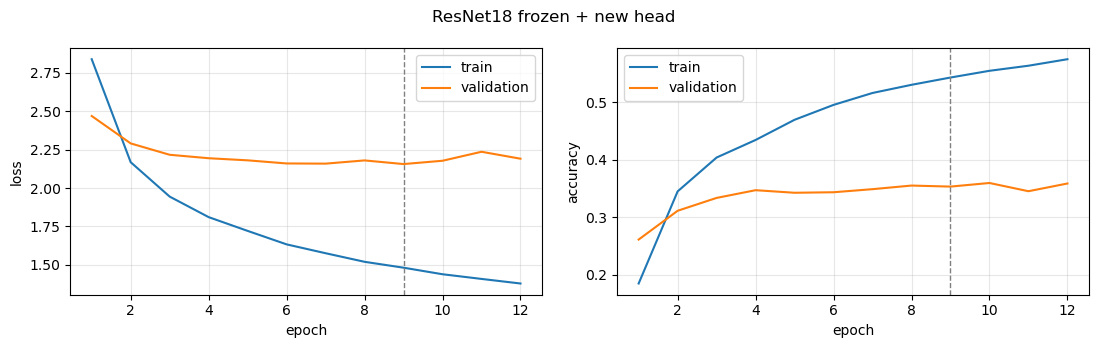

head only: best validation accuracy 0.353 at epoch 9 (144 s)


In [5]:
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)      # the head only (S07)
history_head = fit_transfer(model, optimizer, max_epochs=15, patience=3)
acc_head = history_head["val_acc"][history_head["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_style_head.pt")
plot_history(history_head, "ResNet18 frozen + new head", "resnet_style_head_curves.png")
print(f"head only: best validation accuracy {acc_head:.3f} at epoch {history_head['best_epoch']} "
      f"({history_head['time_s']:.0f} s)")

**Reading.** Before training, the new head predicts at chance level (val acc 0.035 vs 0.037); its loss (3.73) is slightly above ln 27 = 3.30 because the random head is a little over-confident, which is expected.

- **Large gain over the baseline.** With only 13,851 trained parameters, the frozen ResNet reaches **0.353 validation accuracy**, about 3 times the logistic regression on pixels (0.112) and almost 10 times chance. The ImageNet features (textures, shapes, edges) are much more useful for styles than raw pixels.
- **Early stopping.** Validation loss reaches its minimum at epoch 9 (2.156), and does not improve for the next 3 epochs, so training stops at epoch 12 and the weights of epoch 9 are reloaded. Epoch 10 has a slightly higher accuracy (0.360), but the difference is within noise (less than 10 images).
- **Mild over-fitting.** Train accuracy keeps rising (0.575) while validation accuracy plateaus around 0.35 from epoch 4. The head has learned what it can from frozen features; to go further, we need to adapt the features themselves (fine-tuning, section B).
- **Cost.** 144 s on CPU for 12 epochs.

## 4. Fine-tune the last block 
`layer4` computes the most specific features, the ones most tied to ImageNet photos. Paintings are "very different" data (S07): we unfreeze `layer4` and train it with the head, with **two learning rates** (parameter groups): small for the pretrained weights (we only adjust them, we do not want to destroy them), larger for the head.

In [6]:
for p in model.layer4.parameters():
    p.requires_grad = True
optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-4},
                              {"params": model.fc.parameters(), "lr": 1e-3}])
print(f"trainable: {count_parameters(model, trainable_only=True):,} of {count_parameters(model):,} parameters "
      f"(layer4: {count_parameters(model.layer4):,})")

trainable: 8,407,579 of 11,190,363 parameters (layer4: 8,393,728)


epoch  1 | train loss 1.726 acc 0.452 | val loss 2.016 acc 0.379 | 27 s
epoch  2 | train loss 0.928 acc 0.702 | val loss 2.256 acc 0.381 | 41 s
epoch  3 | train loss 0.425 acc 0.885 | val loss 2.494 acc 0.398 | 55 s
epoch  4 | train loss 0.176 acc 0.963 | val loss 2.849 acc 0.370 | 68 s
early stopping: no improvement for 3 epochs


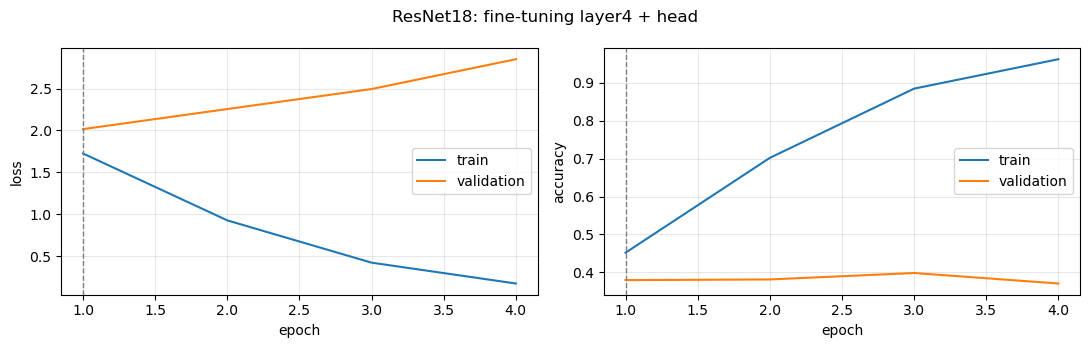

fine-tuned: best validation accuracy 0.379 at epoch 1 (68 s)


In [7]:
history_ft = fit_transfer(model, optimizer, max_epochs=10, patience=3)
acc_ft = history_ft["val_acc"][history_ft["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_style_finetuned.pt")
plot_history(history_ft, "ResNet18: fine-tuning layer4 + head", "resnet_style_finetune_curves.png")
print(f"fine-tuned: best validation accuracy {acc_ft:.3f} at epoch {history_ft['best_epoch']} "
      f"({history_ft['time_s']:.0f} s)")

**Reading.** Unfreezing layer4 gives a small gain at first: **0.379 validation accuracy at epoch 1**, vs 0.353 for the head only. But the model over-fits very fast: train accuracy jumps from 0.45 to 0.96 in 4 epochs, while validation loss **increases** (2.02 → 2.85) and validation accuracy stays flat around 0.38. Layer4 has about 8 million parameters and only ~5,700 training images, so with lr = 1e-4 it memorises the training set. Early stopping keeps the weights of epoch 1. Next step (one change only): divide the learning rate of layer4 by 10 (1e-5).

### Second attempt: a 10× smaller learning rate for layer4 (one change at a time, S08)
Same experiment as on the genres: restart from the head-only model and fine-tune `layer4` with lr = 1e-5.

epoch  1 | train loss 1.484 acc 0.527 | val loss 2.218 acc 0.363 | 20 s
epoch  2 | train loss 1.225 acc 0.614 | val loss 2.264 acc 0.352 | 39 s
epoch  3 | train loss 1.062 acc 0.673 | val loss 2.288 acc 0.360 | 53 s
epoch  4 | train loss 0.890 acc 0.729 | val loss 2.341 acc 0.371 | 67 s
early stopping: no improvement for 3 epochs


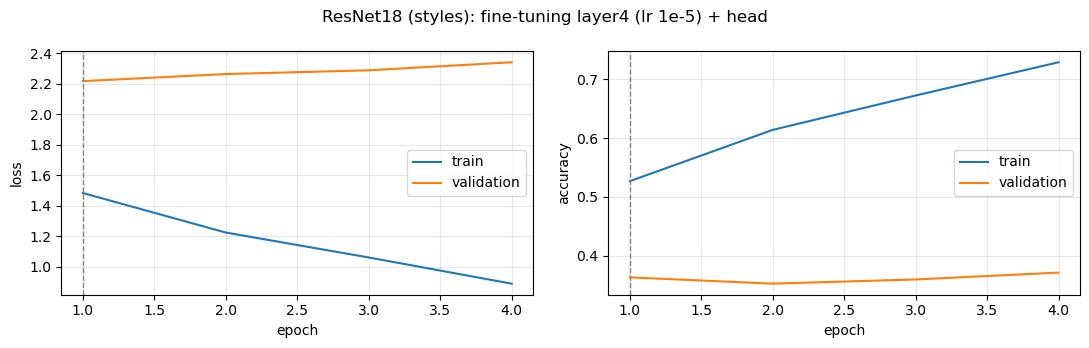

fine-tuned (layer4 lr 1e-5): best validation accuracy 0.363 at epoch 1 (67 s)


In [8]:
model.load_state_dict(torch.load(MODEL_DIR / "resnet18_style_head.pt", map_location=device))   # back to the head-only model
optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-5},
                              {"params": model.fc.parameters(), "lr": 1e-3}])
history_ft2 = fit_transfer(model, optimizer, max_epochs=10, patience=3)
acc_ft2 = history_ft2["val_acc"][history_ft2["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_style_finetuned_lr1e-5.pt")
plot_history(history_ft2, "ResNet18 (styles): fine-tuning layer4 (lr 1e-5) + head", "resnet_style_finetune_lr1e-5_curves.png")
print(f"fine-tuned (layer4 lr 1e-5): best validation accuracy {acc_ft2:.3f} at epoch {history_ft2['best_epoch']} "
      f"({history_ft2['time_s']:.0f} s)")

**Reading.** Dividing the learning rate of layer4 by 10 (one change only) **slows down over-fitting** but does not remove it: train accuracy now rises more gently (0.53 → 0.73 in 4 epochs, vs 0.45 → 0.96 with lr 1e-4), but validation loss still increases from the first epoch (2.22 → 2.34). Best validation accuracy is **0.363**, slightly below lr 1e-4 (0.379) and close to the head only (0.353).

The three ResNet variants are within about 3 points of each other, which is the size of the noise on ~1,200 validation images (±2–3 points). Conclusion: with ~5,700 training images for 27 styles, fine-tuning layer4 brings little or nothing; the limit is the amount of data per style, not the learning rate.

## 5. Head alone vs fine-tuned (on validation)
The model is chosen on **validation** (S04); the test set is used only once, in the next section.

head only                    validation accuracy 0.353
fine-tuned, layer4 lr 1e-4   validation accuracy 0.379
fine-tuned, layer4 lr 1e-5   validation accuracy 0.363

model chosen on validation: fine-tuned, layer4 lr 1e-4 | check: 0.379


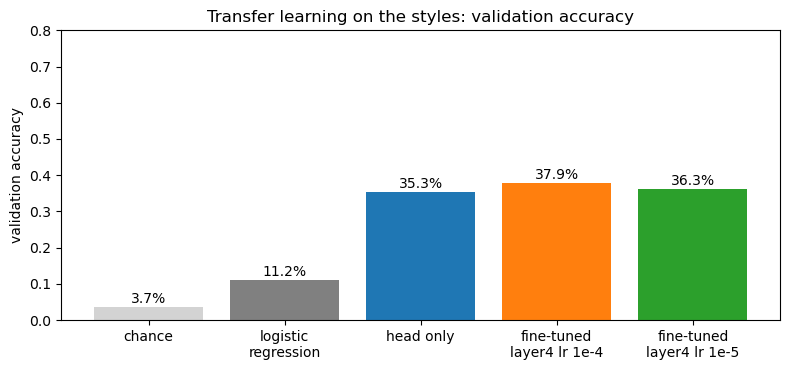

In [9]:
candidates = {
    "resnet18_style_head": ("head only", acc_head, "resnet18_style_head.pt"),
    "resnet18_style_finetuned_lr1e-4": ("fine-tuned, layer4 lr 1e-4", acc_ft, "resnet18_style_finetuned.pt"),
    "resnet18_style_finetuned_lr1e-5": ("fine-tuned, layer4 lr 1e-5", acc_ft2, "resnet18_style_finetuned_lr1e-5.pt"),
}
for key, (label, acc, _) in candidates.items():
    print(f"{label:28s} validation accuracy {acc:.3f}")

chosen = max(candidates, key=lambda k: candidates[k][1])           # best validation accuracy
model.load_state_dict(torch.load(MODEL_DIR / candidates[chosen][2], map_location=device))
print("\nmodel chosen on validation:", candidates[chosen][0],
      f"| check: {evaluate(model, val_loader, loss_fn)[1]:.3f}")

names = ["chance", "logistic\nregression"] + [v[0].replace(", ", "\n") for v in candidates.values()]
vals = [1 / C, BASE["val_accuracy"]] + [v[1] for v in candidates.values()]
plt.figure(figsize=(8, 3.8))
plt.bar(names, vals, color=["lightgrey", "grey", "tab:blue", "tab:orange", "tab:green"])
for i, v in enumerate(vals):
    plt.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.ylabel("validation accuracy"); plt.ylim(0, 0.8); plt.title("Transfer learning on the styles: validation accuracy")
plt.tight_layout(); plt.savefig(FIG_DIR / "resnet_style_head_vs_finetuned.png", dpi=150); plt.show()

## 6. Final evaluation on the test set (once)
The model chosen on validation is now measured **once** on the test images (S04).

TEST accuracy (fine-tuned, layer4 lr 1e-4) = 0.366   | logistic regression 0.115 | chance 0.037


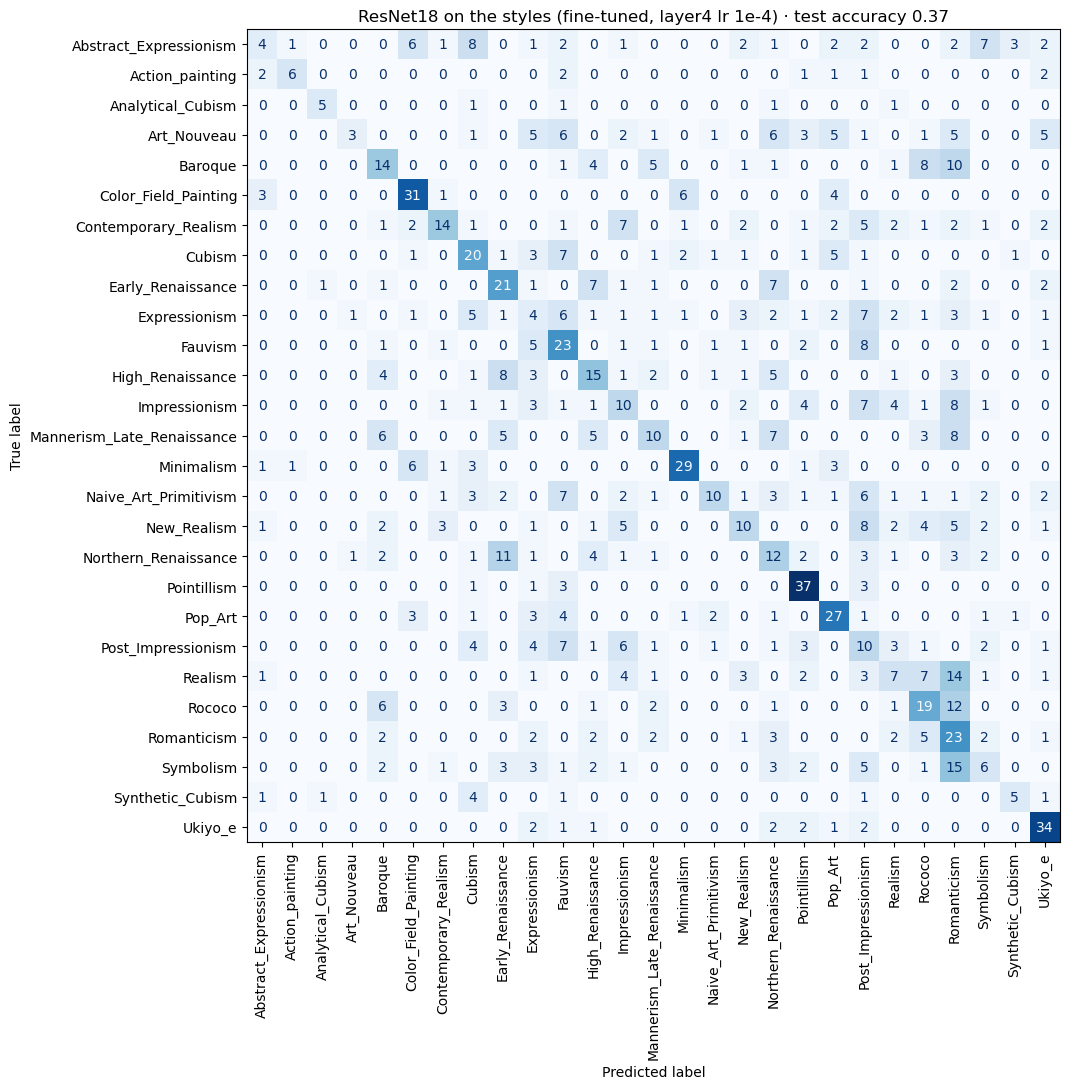

  Pointillism                  0.82   (45 test images)
  Ukiyo_e                      0.76   (45 test images)
  Color_Field_Painting         0.69   (45 test images)
  Minimalism                   0.64   (45 test images)
  Pop_Art                      0.60   (45 test images)
  Analytical_Cubism            0.56   (9 test images)
  Fauvism                      0.51   (45 test images)
  Romanticism                  0.51   (45 test images)
  Early_Renaissance            0.47   (45 test images)
  Cubism                       0.44   (45 test images)
  Rococo                       0.42   (45 test images)
  Action_painting              0.40   (15 test images)
  Synthetic_Cubism             0.36   (14 test images)
  High_Renaissance             0.33   (45 test images)
  Baroque                      0.31   (45 test images)
  Contemporary_Realism         0.31   (45 test images)
  Northern_Renaissance         0.27   (45 test images)
  Impressionism                0.22   (45 test images)
  Mannerism

In [10]:
chosen_label = candidates[chosen][0]
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
model.eval()
with torch.no_grad():
    y_pred = torch.cat([model(xb.to(device)).argmax(1).cpu() for xb, _ in test_loader]).numpy()
y_true = y_all[torch.as_tensor(idx["test"])].numpy()
print(f"TEST accuracy ({chosen_label}) = {test_acc:.3f}   | logistic regression {BASE['test_accuracy']:.3f} | chance {1 / C:.3f}")

cm = confusion_matrix(y_true, y_pred, labels=range(C))
fig, ax = plt.subplots(figsize=(12, 11))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
ax.set_title(f"ResNet18 on the styles ({chosen_label}) · test accuracy {test_acc:.2f}"); fig.tight_layout()
fig.savefig(FIG_DIR / "resnet_style_confusion_test.png", dpi=150); plt.show()

per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda t: -t[1]):
    print(f"  {name:28s} {acc:.2f}   ({cm[class_names.index(name)].sum()} test images)")
off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
if off[i, j] > 0:
    print(f"most frequent mistake: true '{class_names[i]}' predicted as '{class_names[j]}' ({off[i, j]} times)")

**Reading.** The chosen model (fine-tuned layer4, lr 1e-4, selected on validation) reaches **0.37 test accuracy**, very close to its validation accuracy (0.379): the test set confirms the choice. This is **more than 3 times the logistic regression** (0.114) and 10 times chance (0.037).

- **Styles with a strong visual signature are well recognised**: Pointillism (0.82), Ukiyo-e (0.76), Color Field Painting (0.69), Minimalism (0.64), Pop Art (0.60). These styles are defined by texture, flat colour areas or graphic shapes, which is exactly what ImageNet features capture.
- **Mistakes are between historically close styles.** Romanticism acts as a "catch-all" for figurative 18th–19th century paintings: Symbolism → Romanticism (15 times, the most frequent mistake), Realism → Romanticism (14), Rococo → Romanticism (12), Baroque → Romanticism (10). Northern Renaissance is confused with Early Renaissance (11 times): same period, similar techniques.
- **Hardest styles**: Art Nouveau (0.07), Expressionism and Abstract Expressionism (0.09). They are broad movements with very diverse paintings, so there is no single visual pattern to learn.
- **Small classes are now predicted** (Analytical Cubism 0.56, Action painting 0.40, Synthetic Cubism 0.36), while the baseline never predicted them (0.00). With only 9 to 15 test images, these scores are noisy.

## 7. Cost for the kiosk
One photo → one style, on **one CPU thread** (a modest kiosk): we time the whole network on one image (median of 50 runs).

In [11]:
cpu_model = model.to("cpu").eval()
x_one = X_img[:1]
prev = torch.get_num_threads(); torch.set_num_threads(1)
with torch.no_grad():
    for _ in range(5):
        cpu_model(x_one)
    times = []
    for _ in range(50):
        t0 = time.perf_counter(); cpu_model(x_one); times.append((time.perf_counter() - t0) * 1000)
torch.set_num_threads(prev)
ms = float(np.median(times))
size_mb = sum(p.numel() * p.element_size() for p in cpu_model.parameters()) / 1e6

result = {"model": chosen, "label": LABEL, "test_accuracy": round(float(test_acc), 4),
          "cpu_ms_per_image": round(ms, 2), "n_parameters": count_parameters(cpu_model),
          "size_mb": round(size_mb, 1), "train_time_s": round(history_head["time_s"] + history_ft["time_s"], 1),
          "n_classes": C, "img_size": IMG_SIZE,
          "val_acc_head_only": round(acc_head, 4), "val_acc_finetuned_lr1e-4": round(acc_ft, 4),
          "val_acc_finetuned_lr1e-5": round(acc_ft2, 4)}
(RES_DIR / "resnet_style.json").write_text(json.dumps(result, indent=2))
print(json.dumps(result, indent=2))

{
  "model": "resnet18_style_finetuned_lr1e-4",
  "label": "style",
  "test_accuracy": 0.3658,
  "cpu_ms_per_image": 13.23,
  "n_parameters": 11190363,
  "size_mb": 44.8,
  "train_time_s": 212.2,
  "n_classes": 27,
  "img_size": 128,
  "val_acc_head_only": 0.3533,
  "val_acc_finetuned_lr1e-4": 0.3792,
  "val_acc_finetuned_lr1e-5": 0.3631
}


## 8. Comparison and conclusions
All the models of the team **on the styles** (same split), read from `results/*.json`.

model                              test acc  ms/image      MB
chance                                0.037
baseline_logreg_style                 0.115      0.14     2.7
resnet18_style_finetuned_lr1e-4       0.366     13.23    44.8


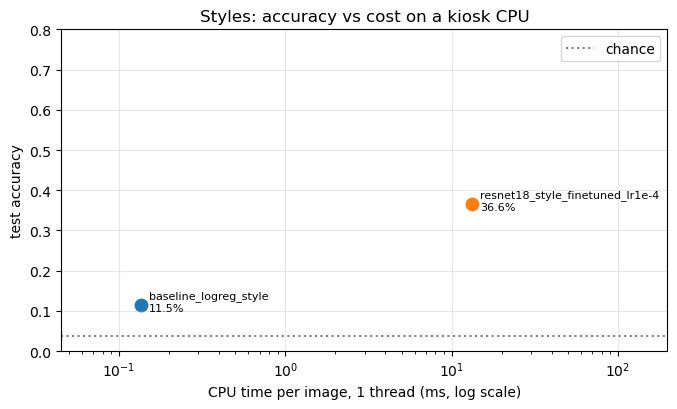

In [12]:
rows = []
for p in sorted(RES_DIR.glob("*.json")):
    r = json.loads(p.read_text())
    if "test_accuracy" in r and "cpu_ms_per_image" in r and r.get("n_classes") == C:   # same task only
        rows.append((r["model"], r["test_accuracy"], r["cpu_ms_per_image"], r.get("size_mb")))
rows.sort(key=lambda t: t[1])

print(f"{'model':34s} {'test acc':>8s} {'ms/image':>9s} {'MB':>7s}")
print(f"{'chance':34s} {1 / C:8.3f}")
for m, a, t, s in rows:
    print(f"{m:34s} {a:8.3f} {t:9.2f} {s if s is not None else '':>7}")

plt.figure(figsize=(7, 4.2))
for m, a, t, s in rows:
    plt.scatter(t, a, s=80)
    plt.annotate(f"{m}\n{a:.1%}", (t, a), xytext=(6, -4), textcoords="offset points", fontsize=8)
ts = [t for _, _, t, _ in rows]
plt.xlim(min(ts) / 3, max(ts) * 15)       # room for the labels
plt.axhline(1 / C, ls=":", c="grey", label="chance")
plt.xscale("log"); plt.xlabel("CPU time per image, 1 thread (ms, log scale)"); plt.ylabel("test accuracy")
plt.ylim(0, 0.8); plt.title("Styles: accuracy vs cost on a kiosk CPU"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_style_accuracy_vs_cpu.png", dpi=150); plt.show()

## Conclusions (styles)

| Model | Test acc | CPU ms / image | Size |
|---|---|---|---|
| Chance | 0.037 | – | – |
| Logistic regression on pixels | 0.115 | 0.14 | 2.7 MB |
| ResNet18 fine-tuned (layer4, lr 1e-4) | **0.366** | 13.2 | 44.8 MB |

1. **Transfer learning is the right approach.** On the same 27 styles and the same split, the pretrained ResNet18 is **3 times more accurate** than the logistic regression (0.366 vs 0.115). Raw pixels only capture colour and brightness; ImageNet features capture textures and shapes, which define a style.
2. **Fine-tuning brings little.** Head only, fine-tuned lr 1e-4 and fine-tuned lr 1e-5 are within 3 points on validation (0.353 / 0.379 / 0.363), which is the size of the noise. With about 200 training images per style, layer4 over-fits within 1–2 epochs, and a smaller learning rate only slows this down.
3. **The cost is acceptable for a kiosk.** 13 ms per image on one CPU thread (about 75 images per second) and 45 MB on disk. A visitor takes one photo at a time, so the answer is instant even on a modest CPU. The ResNet is 100 times slower than the baseline, but still far below what a user can notice.
4. **Limits.** 37 % on 27 styles is still low: the model confuses historically close movements (Symbolism / Romanticism, Northern / Early Renaissance), and broad movements (Art Nouveau, Expressionism) are poorly recognised. For the museum guide, we suggest showing the **top 2–3 styles** rather than a single answer, or grouping styles into broader periods.

**Recommendation to the director:** a neural network is worth it. The pretrained ResNet18 runs comfortably on a kiosk CPU, and it is the only model that gives useful answers on styles.